In [78]:
# (Setup - you already have this in your notebook, skip it)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_excel('Project Data.xlsx')  #tirar o nova

df = data.copy()
df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


## 1.3 Missing Values


### 1.3.1 Identifying Missing Values Across Variables


In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Patient ID                 10008 non-null  int64         
 1   Age                        9952 non-null   float64       
 2   Gender                     10008 non-null  str           
 3   City of Residence          10008 non-null  str           
 4   Profession                 10008 non-null  str           
 5   Insurance Provider         8098 non-null   str           
 6   Family History             8015 non-null   str           
 7   Education Level            9979 non-null   str           
 8   Marital Status             10008 non-null  str           
 9   Visit Date                 10008 non-null  datetime64[us]
 10  Department                 10008 non-null  str           
 11  Consultation Duration      10008 non-null  int64         
 12  Satisfaction Le

In [80]:
# Quantidade e percentagem de missing values por coluna
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percent.round(2)
})

# Mostrar apenas colunas com missing values
missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage (%)
Age,56,0.56
Insurance Provider,1910,19.08
Family History,1993,19.91
Education Level,29,0.29
Approximate Annual Income,154,1.54
Insurance Coverage,50,0.50


### 1.3.2 Analysing Missing Data Patterns

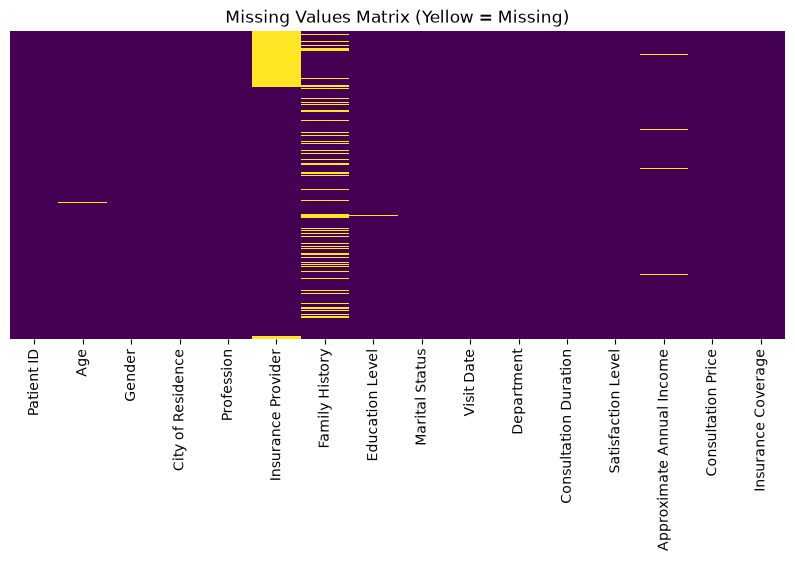

In [81]:
# Matriz de calor simples com nulos por coluna
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Matrix (Yellow = Missing)')
plt.show()



The missing value heatmap above illustrates the distribution and structure of missingness across the dataset:

* **Primary Contributors to Missingness:** Missing data is overwhelmingly concentrated in two categorical features: `Insurance Provider` (1,910 missing values) and `Family History` (1,993 missing values).
* **Patient-Level Systematic Patterns:** The continuous vertical block observed in `Insurance Provider` indicates systematic missingness at the patient level, where specific patients lack insurance provider information across all recorded consultations.
* **Random Sporadic Missingness:** In contrast, `Family History` exhibits a scattered pattern across rows, representing sporadic non-reporting during individual clinical visits rather than a structural omission.
* **Low-Volume Omissions:** Demographic and financial features (`Age`, `Education Level`, `Approximate Annual Income`, and `Insurance Coverage`) display isolated, minimal gaps, confirming that missing values in these fields represent a minor fraction of the total observations.

### 1.3.3 Applying Imputation Strategies

In [82]:
df_imputed = df.copy()

for col in ['Age', 'Education Level']:
    df_imputed[col] = df_imputed.groupby('Patient ID')[col].ffill().bfill()

df_imputed['Insurance Provider'] = df_imputed.groupby('Patient ID')['Insurance Provider'].ffill().bfill()

rate_by_provider = {0.0: 'None', 0.8: 'Provider A', 0.9: 'Provider B', 0.7: 'Provider C', 1.0: 'Provider D'}
ratio = (df_imputed['Insurance Coverage'] / df_imputed['Consultation Price']).round(1)

df_imputed['Insurance Provider'] = df_imputed['Insurance Provider'].fillna(ratio.map(rate_by_provider))

provider_rates = {'None': 0.0, 'Provider A': 0.8, 'Provider B': 0.9, 'Provider C': 0.7, 'Provider D': 1.0}
expected_rate = df_imputed['Insurance Provider'].map(provider_rates)

df_imputed['Insurance Coverage'] = df_imputed['Insurance Coverage'].fillna(expected_rate * df_imputed['Consultation Price'])

income_median = df_imputed.groupby('Patient ID')['Approximate Annual Income'].transform('median')

df_imputed['Approximate Annual Income'] = df_imputed['Approximate Annual Income'].fillna(income_median)

df_imputed['Family History'] = df_imputed['Family History'].fillna('Unknown')

print("Missing values after imputation:")
print(df_imputed.isnull().sum())

Missing values after imputation:
Patient ID                   0
Age                          0
Gender                       0
City of Residence            0
Profession                   0
Insurance Provider           0
Family History               0
Education Level              0
Marital Status               0
Visit Date                   0
Department                   0
Consultation Duration        0
Satisfaction Level           0
Approximate Annual Income    0
Consultation Price           0
Insurance Coverage           0
dtype: int64


### 1.3.3 Applying Imputation Strategies

To handle the missing data identified across the dataset, a multi-tiered imputation strategy was implemented based on domain rules, patient-level consistency, and mathematical relationships between variables:

* **Demographic Variables (`Age` & `Education Level`):** 
  Since age and formal education level are invariant characteristics for a given individual across the short observational timeframe, missing values were propagated directly from each patient's other recorded clinical visits (`ffill().bfill()` grouped by `Patient ID`). This restores true historical values without introducing synthetic noise.

* **Insurance Provider (`Insurance Provider`):** 
  Imputation was carried out in two sequential steps:
  1. *Patient-Level Propagation:* Missing provider values were first filled using known insurance records from the same patient's other visits.
  2. *Deterministic Coverage Ratio Mapping:* For patients with no provider recorded across all visits, the provider was reverse-engineered using the exact ratio between insurance coverage and consultation price ($\text{Ratio} = \frac{\text{Insurance Coverage}}{\text{Consultation Price}}$). Since each provider operates on a fixed coverage rate ($0.0 \rightarrow \text{None}$, $0.7 \rightarrow \text{Provider C}$, $0.8 \rightarrow \text{Provider A}$, $0.9 \rightarrow \text{Provider B}$, $1.0 \rightarrow \text{Provider D}$), the underlying provider was mapped deterministically.

* **Insurance Coverage (`Insurance Coverage`):** 
  Missing values were imputed deterministically by applying the corresponding insurance provider's coverage rate to the total consultation cost ($\text{Coverage} = \text{Provider Rate} \times \text{Consultation Price}$). This preserves exact mathematical consistency across financial fields.

* **Approximate Annual Income (`Approximate Annual Income`):** 
  Because annual income exhibits minor reporting variations across visits, missing entries were imputed using the median income calculated per patient (`transform('median')`). This approach reduces distortion from single-visit anomalies while preserving zero-income entries for young or unemployed patients.

* **Family History (`Family History`):** 
  Given the sporadic nature of missing medical history entries and the categorical structure of the feature, remaining missing values were explicitly imputed as `'Unknown'`. This avoids fabricating clinical background while retaining all patient records for subsequent analytical steps.